<a href="https://colab.research.google.com/github/Harjotbahra22/Twenty5/blob/main/Midterm_Research_Plan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ---- Cell 1: setup + list the files we will use ----
import requests, os, numpy as np, pandas as pd, scipy.io as sio
from scipy.ndimage import uniform_filter1d

FS = 1926                                   # EMG samples per second
good_ch = [0,1,2,3,4,5,6,8,9,10,11]         # 11 of the 12 electrodes; index 7 (electrode 8) is unreliable

# Ask the dataset website for the list of all its files.
# The "User-Agent" header makes the site treat this like a browser; without it the reply came back empty.
hdr = {"User-Agent": "Mozilla/5.0", "Accept": "application/json"}
url = ("https://dataverse.harvard.edu/api/datasets/:persistentId/versions/:latest/files"
       "?persistentId=doi:10.7910/DVN/1Z3IOM&limit=500")
listing = requests.get(url, headers=hdr, timeout=60).json()['data']

# Make a lookup: file name -> the file's ID number (the ID is what the download link needs).
ids = {f['dataFile']['filename']: f['dataFile']['id'] for f in listing}
print("total files in dataset:", len(ids))

# Keep only the EMG files: names ending in "_ex1.mat".
# (Names ending in "_ex1_orig.mat" are the raw sensor files WITHOUT EMG, so  skip them.)
ex1 = sorted(n for n in ids if n.endswith('_ex1.mat'))
assert all('_orig' not in n for n in ex1)    # safety check: stop if a wrong file slipped in

print("EMG files found:", len(ex1))
for n in ex1:
    print(n)

total files in dataset: 244
EMG files found: 45
S010_ex1.mat
S011_ex1.mat
S012_ex1.mat
S013_ex1.mat
S014_ex1.mat
S015_ex1.mat
S016_ex1.mat
S017_ex1.mat
S018_ex1.mat
S019_ex1.mat
S020_ex1.mat
S021_ex1.mat
S022_ex1.mat
S023_ex1.mat
S024_ex1.mat
S026_ex1.mat
S027_ex1.mat
S028_ex1.mat
S029_ex1.mat
S030_ex1.mat
S031_ex1.mat
S032_ex1.mat
S033_ex1.mat
S034_ex1.mat
S035_ex1.mat
S036_ex1.mat
S037_ex1.mat
S038_ex1.mat
S039_ex1.mat
S040_ex1.mat
S101_ex1.mat
S102_ex1.mat
S103_ex1.mat
S104_ex1.mat
S105_ex1.mat
S106_ex1.mat
S107_ex1.mat
S108_ex1.mat
S109_ex1.mat
S110_ex1.mat
S111_ex1.mat
S112_ex1.mat
S113_ex1.mat
S114_ex1.mat
S115_ex1.mat


Extract data from one file to check the data inside of each file and what is usbale

In [ ]:
name = 'S010_ex1.mat' #inspecting one file
os.system(f'wget -q -c -O {name} "https://dataverse.harvard.edu/api/access/datafile/{ids[name]}"')

# whosmat lists each variable as (name, shape, type) WITHOUT loading the data into memory
for var_name, shape, kind in sio.whosmat(name):
    print(f"{var_name:28s} {str(shape):18s} {kind}")


ts                           (7748672, 1)       double
grasp                        (7748672, 1)       int8
object                       (7748672, 1)       int8
grasprepetition              (7748672, 1)       int8
objectrepetition             (7748672, 1)       int8
position                     (7748672, 1)       int8
objectpart                   (7748672, 1)       int8
dynamic                      (7748672, 1)       int8
emg                          (7748672, 12)      single
acc                          (7748672, 36)      single
tobiits                      (7748672, 1)       double
gazepoint                    (7748672, 2)       single
gazepoint_invalid            (7748672, 1)       int8
gazepoint3D                  (7748672, 3)       single
gazepoint3D_invalid          (7748672, 1)       int8
pupildiameterleft            (7748672, 1)       single
pupildiameterleft_invalid    (7748672, 1)       int8
pupildiameterright           (7748672, 1)       single
pupildiameterright_invalid   (

In [ ]:
#  download ONE file and print the parts of it that are usable
name = 'S010_ex1.mat'

# Download it into Colab. -c resumes if interrupted; -q hides the progress noise.
os.system(f'wget -q -c -O {name} "https://dataverse.harvard.edu/api/access/datafile/{ids[name]}"')
print("file size (GB):", round(os.path.getsize(name) / 1e9, 2))

# Load ONLY these four fields to save memory.
d = sio.loadmat(name, variable_names=['emg', 'regrasp', 'regrasprepetition', 'gazepoint_invalid'])
emg = d['emg']                               # muscle signal: rows = moments in time, 12 columns = electrodes, in volts
grasp = d['regrasp'].ravel()                 # which grasp is being asked for at each moment (0 = rest)
rep = d['regrasprepetition'].ravel()         # which attempt number; negative = not a real trial
gaze_bad = d['gazepoint_invalid'].ravel()    # 1 = eye tracker lost the eye at that moment

# Basic size and length
print("EMG shape (rows, electrodes):", emg.shape)
print("recording length (min):", round(emg.shape[0] / FS / 60, 1))

# Real trials only: drop rows where the repetition number is not positive.
ok = rep > 0
print("rows kept as real trials:", ok.sum(), "of", len(ok))

#rows per grasp label (among real trials). Confirm that 0 is a large "rest" group.
labels, counts = np.unique(grasp[ok], return_counts=True)
print("grasp label -> rows:", dict(zip(labels.tolist(), counts.tolist())))

#  repetitions for each grasp
print("repetition numbers present:", np.unique(rep[ok]))

# Share of rows where gaze was lost
print("gaze invalid share:", round(gaze_bad[ok].mean(), 3))

# Average absolute signal per electrode (in microvolts). One electrode that is tiny or huge is a red flag;
# electrode 8 (index 7) should look odd.
print("mean |EMG| per electrode (uV):", np.round(np.abs(emg).mean(axis=0) * 1e6, 1))

# First few raw EMG values, so you can see what the numbers look like
print(emg[:3, :4])

os.remove(name)                              # delete the big file again to free disk space

file size (GB): 1.48
EMG shape (rows, electrodes): (7748672, 12)
recording length (min): 67.1
rows kept as real trials: 5902768 of 7748672
grasp label -> rows: {0: 2673532, 1: 326001, 2: 290537, 3: 295004, 4: 294700, 5: 326844, 6: 324195, 7: 328652, 8: 342114, 9: 360232, 10: 340957}
repetition numbers present: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]
gaze invalid share: 0.085
mean |EMG| per electrode (uV): [24.2 20.8  5.8  2.9  3.9  3.1  4.1  0.2 20.9  6.4  3.2  4. ]
[[-5.0039904e-07  1.4964401e-06 -1.4122292e-05  6.0682669e-06]
 [ 1.7071146e-07  3.3427011e-06 -1.3786534e-05  2.7111646e-06]
 [ 8.4182199e-07  4.0139621e-06 -1.2611576e-05 -3.1636478e-06]]


In [ ]:
def summarize_file(path):
    """Open one EMG file and return a few numbers describing that subject."""

    # 1. Check that the fields we need are really in this file.
    needed = ['emg', 'regrasp', 'regrasprepetition', 'gazepoint_invalid']
    present = [v[0] for v in sio.whosmat(path)]
    missing = [v for v in needed if v not in present]
    if missing:
        return dict(ratio_mean=np.nan, ratio_median=np.nan, rest_frac=np.nan,
                    gaze_invalid=np.nan, n_channels=0, note='missing: ' + ','.join(missing))

    # 2. Load only those fields.
    d = sio.loadmat(path, variable_names=needed)
    emg = d['emg'] * 1e6                         # volts -> microvolts; rows = time, columns = electrodes
    grasp = d['regrasp'].ravel()                 # 0 = rest, 1..10 = which grasp
    ok = d['regrasprepetition'].ravel() > 0      # real trials only
    rest = ok & (grasp == 0)
    active = ok & (grasp > 0)

    # 3. Pick the good electrodes automatically: drop any whose average signal is tiny
    #    (less than 10% of the typical electrode), e.g. the dead one.
    level = np.abs(emg[ok]).mean(axis=0)         # average |signal| of each electrode
    good = np.where(level > 0.1 * np.median(level))[0]

    # 4. For each good electrode, compute the active/rest ratio two ways.
    mean_ratios, median_ratios = [], []
    for c in good:
        x = emg[:, c]
        x = x - x.mean()                         # remove the constant offset
        a, r = np.abs(x[active]), np.abs(x[rest])
        mean_ratios.append(a.mean() / r.mean())              # sensitive to spikes
        median_ratios.append(np.median(a) / np.median(r))    # barely affected by spikes

    # 5. One number per subject for each method: the middle value across electrodes.
    return dict(ratio_mean=np.median(mean_ratios),
                ratio_median=np.median(median_ratios),
                rest_frac=rest.sum() / ok.sum(),
                gaze_invalid=d['gazepoint_invalid'].ravel()[ok].mean(),
                n_channels=len(good),
                note='ok')

In [ ]:
out = 'subject_summary_simple.csv'               # results file, saved after every subject
done = pd.read_csv(out) if os.path.exists(out) else pd.DataFrame()
rows = done.to_dict('records')                   # resume: keep rows already finished
finished = set(done['subject']) if len(done) else set()

for name in ex1:                                 # use ex1[:2] for a quick test first
    sid = name[:4]                               # subject ID, e.g. "S010"
    if sid in finished: continue                 # skip subjects already done
    os.system(f'wget -q -c -O {name} "https://dataverse.harvard.edu/api/access/datafile/{ids[name]}"')
    rows.append(dict(subject=sid, **summarize_file(name)))
    os.remove(name)                              # free the disk
    pd.DataFrame(rows).to_csv(out, index=False)  # save progress after every subject
    print(sid, 'done')
print(pd.DataFrame(rows))

S010 done
S011 done
S012 done
S013 done
S014 done
S015 done
S016 done
S017 done
S018 done
S019 done
S020 done
S021 done
S022 done
S023 done
S024 done
S026 done
S027 done
S028 done
S029 done
S030 done
S031 done
S032 done
S033 done
S034 done
S035 done
S036 done
S037 done
S038 done
S039 done
S040 done
S101 done
S102 done
S103 done
S104 done
S105 done
S106 done
S107 done
S108 done
S109 done
S110 done
S111 done
S112 done
S113 done
S114 done
S115 done
   subject  ratio_mean  ratio_median  rest_frac  gaze_invalid  n_channels  \
0     S010    2.223123      1.622721   0.452929      0.085239          11   
1     S011         NaN           NaN        NaN           NaN           0   
2     S012    2.620220      1.880378   0.515046      0.116164          11   
3     S013    2.341692      1.769762   0.563582      0.057571          11   
4     S014    2.145801      1.461960   0.511620      0.167776          11   
5     S015    2.499189      1.864264   0.513480      0.223659          12   
6     S016 

In [ ]:
   df = pd.read_csv('subject_summary_simple.csv')
   df = df[df['ratio_mean'].notna()].drop(columns=['ratio'])   # keep only the new-method rows
   df.to_csv('subject_summary_simple.csv', index=False)

KeyError: "['ratio'] not found in axis"

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

df = pd.read_csv('subject_summary_simple.csv')
print(df.shape)                                              # expect (45, 7) or similar
print(df[['ratio_mean', 'ratio_median', 'n_channels']].isna().sum())   # expect all 0

(45, 7)
ratio_mean      1
ratio_median    1
n_channels      0
dtype: int64


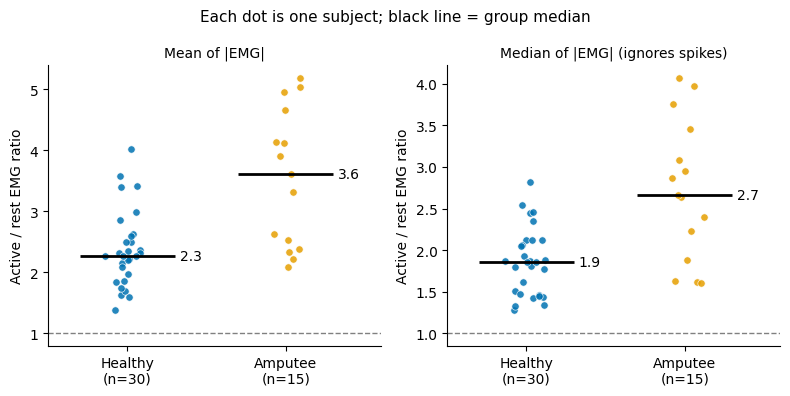

         subjects  ratio_mean  ratio_median  rest_share  gaze_lost  \
group                                                                
Amputee        15        3.62          2.66        0.56       0.11   
Healthy        30        2.27          1.85        0.50       0.09   

         electrodes_min  electrodes_max  
group                                    
Amputee               8              12  
Healthy               0              12  


In [ ]:
# Group label: IDs starting with S1 are amputees (S101-S115). CHECK this against Table 1 of the paper.
df['group'] = np.where(df['subject'].str.startswith('S1'), 'Amputee', 'Healthy')
n = df['group'].value_counts()

colors = {'Healthy': '#0072B2', 'Amputee': '#E69F00'}        # blue / orange: distinguishable for colorblind readers
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
rng = np.random.default_rng(0)

for ax, col, title in zip(axes, ['ratio_mean', 'ratio_median'],
                          ['Mean of |EMG|', 'Median of |EMG| (ignores spikes)']):
    for i, g in enumerate(['Healthy', 'Amputee']):
        y = df.loc[df['group'] == g, col]                    # one value per subject
        x = rng.normal(i, 0.06, len(y))                      # small random shift so dots don't overlap
        ax.scatter(x, y, s=28, color=colors[g], alpha=0.85, edgecolor='white', linewidth=0.5)
        ax.hlines(y.median(), i - 0.3, i + 0.3, color='black', linewidth=2)   # group median
        ax.text(i + 0.33, y.median(), f"{y.median():.1f}", va='center')
    ax.axhline(1, color='gray', linestyle='--', linewidth=1)  # ratio 1 = grasp looks like rest
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f"Healthy\n(n={n['Healthy']})", f"Amputee\n(n={n['Amputee']})"])
    ax.set_xlim(-0.5, 1.6)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel('Active / rest EMG ratio')
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Each dot is one subject; black line = group median', fontsize=11)
plt.tight_layout()
plt.savefig('fig_rest_vs_active.png', dpi=200)               # saved file for your report
plt.show()

# Table for the report: group balance and data quality
summary = df.groupby('group').agg(
    subjects=('subject', 'count'),
    ratio_mean=('ratio_mean', 'median'),
    ratio_median=('ratio_median', 'median'),
    rest_share=('rest_frac', 'mean'),
    gaze_lost=('gaze_invalid', 'mean'),
    electrodes_min=('n_channels', 'min'),
    electrodes_max=('n_channels', 'max')).round(2)
print(summary)



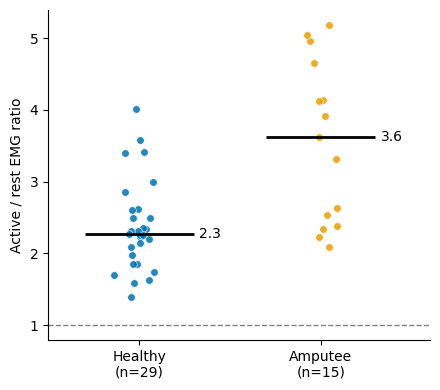

         subjects  rest_share  gaze_lost  electrodes_min  electrodes_max
group                                                                   
Amputee        15        0.56       0.11               8              12
Healthy        29        0.50       0.09              11              12


In [ ]:
df = pd.read_csv('subject_summary_simple.csv')
df['group'] = np.where(df['subject'].str.startswith('S1'), 'Amputee', 'Healthy')
df = df.dropna(subset=['ratio_mean'])                        # drop any subject with no valid ratio
n = df['group'].value_counts()

colors = {'Healthy': '#0072B2', 'Amputee': '#E69F00'}
fig, ax = plt.subplots(figsize=(4.5, 4))
rng = np.random.default_rng(0)
for i, g in enumerate(['Healthy', 'Amputee']):
    y = df.loc[df['group'] == g, 'ratio_mean']
    ax.scatter(rng.normal(i, 0.06, len(y)), y, s=30, color=colors[g],
               alpha=0.85, edgecolor='white', linewidth=0.5)
    ax.hlines(y.median(), i - 0.3, i + 0.3, color='black', linewidth=2)     # group median
    ax.text(i + 0.33, y.median(), f"{y.median():.1f}", va='center')
ax.axhline(1, color='gray', linestyle='--', linewidth=1)    # 1 = grasp looks like rest
ax.set_xticks([0, 1])
ax.set_xticklabels([f"Healthy\n(n={n['Healthy']})", f"Amputee\n(n={n['Amputee']})"])
ax.set_xlim(-0.5, 1.6)
ax.set_ylabel('Active / rest EMG ratio')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('fig_rest_vs_active.png', dpi=200)
plt.show()

df['group'] = np.where(df['subject'].str.startswith('S1'), 'Amputee', 'Healthy')
valid = df[df['note'] == 'ok']                         # drop subjects with a missing field

quality = valid.groupby('group').agg(
    subjects=('subject', 'count'),
    rest_share=('rest_frac', 'mean'),
    gaze_lost=('gaze_invalid', 'mean'),
    electrodes_min=('n_channels', 'min'),
    electrodes_max=('n_channels', 'max')).round(2)
print(quality)

In [ ]:
df = pd.read_csv('subject_summary_simple.csv')
print(df[df['ratio_mean'].isna()][['subject', 'note', 'n_channels', 'gaze_invalid']])

  subject                                               note  n_channels  \
1    S011  missing: regrasp,regrasprepetition,gazepoint_i...           0   

   gaze_invalid  
1           NaN  


15 amputees matched


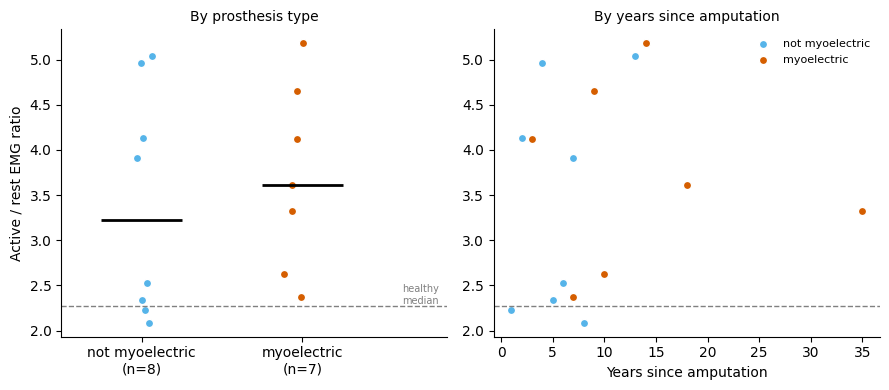

years vs ratio: Spearman rho = 0.23, p = 0.42
                 count  median
type                          
myoelectric          7    3.62
not myoelectric      8    3.22


In [ ]:
# Details of the 15 amputees, typed from Table 1 of the paper
info = pd.DataFrame({
    'subject':    ['S101','S102','S103','S104','S105','S106','S107','S108','S109','S110','S111','S112','S113','S114','S115'],
    'prosthesis': ['cosmetic','cosmetic','myoelectric','myoelectric','body-powered','body-powered','body-powered',
                   'myoelectric','cosmetic','myoelectric','myoelectric','cosmetic','myoelectric','myoelectric','cosmetic'],
    'years':      [2, 4, 3, 18, 6, 5, 7, 9, 1, 14, 10, 13, 7, 35, 8]})

amp = df[['subject', 'ratio_mean']].merge(info, on='subject')         # amputees only
amp['type'] = np.where(amp['prosthesis'] == 'myoelectric', 'myoelectric', 'not myoelectric')
print(len(amp), 'amputees matched')                                   # should say 15

healthy_median = df.loc[~df['subject'].str.startswith('S1'), 'ratio_mean'].median()   # reference line

colors = {'not myoelectric': '#56B4E9', 'myoelectric': '#D55E00'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
rng = np.random.default_rng(0)

for i, t in enumerate(colors):                                         # one group at a time
    sub = amp[amp['type'] == t]
    ax1.scatter(rng.normal(i, 0.05, len(sub)), sub['ratio_mean'], s=35, color=colors[t], edgecolor='white')
    ax1.hlines(sub['ratio_mean'].median(), i - 0.25, i + 0.25, color='black', linewidth=2)   # group median
    ax2.scatter(sub['years'], sub['ratio_mean'], s=35, color=colors[t], edgecolor='white', label=t)

ax1.set_xticks(range(2))
ax1.set_xticklabels([f"{t}\n(n={(amp['type'] == t).sum()})" for t in colors])
ax1.set_xlim(-0.5, 1.9)
ax1.set_ylabel('Active / rest EMG ratio'); ax1.set_title('By prosthesis type', fontsize=10)

ax2.set_xlabel('Years since amputation'); ax2.set_title('By years since amputation', fontsize=10)
ax2.legend(frameon=False, fontsize=8)

for ax in (ax1, ax2):
    ax.axhline(healthy_median, color='gray', linestyle='--', linewidth=1)   # healthy group's middle value
    ax.spines[['top', 'right']].set_visible(False)
ax1.text(1.85, healthy_median, 'healthy\nmedian', fontsize=7, color='gray', va='bottom', ha='right')
plt.tight_layout(); plt.savefig('fig_amputee_details.png', dpi=200); plt.show()

# Two numbers to read next to the plot
from scipy.stats import spearmanr
rho, p = spearmanr(amp['years'], amp['ratio_mean'])
print('years vs ratio: Spearman rho = %.2f, p = %.2f' % (rho, p))
print(amp.groupby('type')['ratio_mean'].agg(['count', 'median']).round(2))